# Issue #2 – Évaluer et améliorer le modèle XGBoost
**Branche : `fix/xgboost-evaluation`**

Objectif : comprendre pourquoi la classe **medium** est presque jamais détectée, essayer des améliorations
**sans fuite de cible**, puis mesurer proprement avant/après sur la même séparation train/test.

Règles suivies dans ce notebook :
1. XGBoost reste le seul algorithme.
2. La séparation train/test est celle du script `train.py` (`test_size=0.2`, `random_state=42`, stratifiée).
3. Tous les choix (hyperparamètres, poids) se font sur un jeu de **validation extrait du train**. Le **test ne sert qu'une fois, à la fin**.
4. On enregistre précision, rappel, F1 par classe, F1 macro, matrice de confusion et AUC dans `reports/`.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# --- Paramètres généraux -----------------------------------------------------
SEED = 42
TEST_SIZE = 0.20          # identique à train.py
VAL_SIZE = 0.20           # part du TRAIN réservée à la validation
SAMPLE_ROWS = 100_000        # ex. 100_000 pour aller plus vite pendant les essais ; None = tout
SAVE_MODEL = False        # True pour sauvegarder aussi le modèle amélioré dans models/

# --- Racine du projet (dossier qui contient le fichier .dvc) ------------------
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "telecom_credit_scoring_data.csv.dvc").exists())
DATA_PATH = ROOT / "telecom_credit_scoring_data.csv"
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

sys.path.insert(0, str(ROOT / "src" / "telecom_mlops"))
from config import FEATURES, TARGET  # noqa: E402  (mêmes variables que train.py)

print("Projet :", ROOT)
print("xgboost", xgboost.__version__, "| scikit-learn", sklearn.__version__)

Projet : C:\Users\User\telecom-credit-risk-mlops
xgboost 3.4.1 | scikit-learn 1.6.1


## 1. Données et cible

In [2]:
data = pd.read_csv(DATA_PATH)
if SAMPLE_ROWS:
    data = data.sample(SAMPLE_ROWS, random_state=SEED).reset_index(drop=True)
print(data.shape)
print("Colonnes NON utilisées par le modèle :", sorted(set(data.columns) - set(FEATURES) - {TARGET}))
print("Colonnes utilisées :", FEATURES)
dist = data[TARGET].value_counts(normalize=True).rename("proportion").to_frame()
dist["effectif"] = data[TARGET].value_counts()
dist

(100000, 15)
Colonnes NON utilisées par le modèle : ['assessment_date', 'customer_id', 'loan_eligibility', 'max_loan_amount_ngn', 'phone_number']
Colonnes utilisées : ['operator', 'credit_score', 'credit_rating', 'tenure_months', 'avg_monthly_spend_ngn', 'recharge_frequency_per_month', 'payment_consistency_score', 'late_payment_count', 'account_type']


,proportion,effectif
default_risk,,
low,0.54760,54760
medium,0.23093,23093
high,0.22147,22147


In [3]:
X = data[FEATURES].copy()
encoder = LabelEncoder()
y = encoder.fit_transform(data[TARGET].astype(str))
CLASSES = encoder.classes_.tolist()          # ['high', 'low', 'medium']
IDS = list(range(len(CLASSES)))
MED = CLASSES.index("medium")
print(CLASSES)

# Même séparation que train.py
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
# Validation = 20 % du train (le test n'est pas touché)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=VAL_SIZE, random_state=SEED, stratify=y_train)
print(f"fit={len(X_fit):,}  val={len(X_val):,}  test={len(X_test):,}")

['high', 'low', 'medium']
fit=64,000  val=16,000  test=20,000


## 2. Audit de fuite de cible
Une fuite = une variable qui contient déjà la réponse (ou en est calculée). Deux signaux :
- une variable **seule** donne un AUC très élevé ;
- retirer une variable fait **chuter** fortement les performances.

`credit_score` et `credit_rating` sont à regarder en premier. **Cet audit ne décide rien tout seul** :
lisez aussi la fiche du jeu de données (README sur Hugging Face) pour savoir comment `default_risk` est généré.

In [4]:
CAT = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
NUM = X.select_dtypes(include=["number"]).columns.tolist()


def make_prep(cat, num):
    return ColumnTransformer([
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median"))]), num),
    ], remainder="drop")


def quick_auc(cols):
    """AUC macro OvR d'un petit XGBoost entraîné sur les colonnes `cols` (jeu fit -> val)."""
    cat = [c for c in cols if c in CAT]
    num = [c for c in cols if c in NUM]
    prep = make_prep(cat, num).fit(X_fit[cols])
    m = XGBClassifier(objective="multi:softprob", n_estimators=120, max_depth=4, learning_rate=0.1,
                      tree_method="hist", random_state=SEED, n_jobs=-1)
    m.fit(prep.transform(X_fit[cols]), y_fit)
    return roc_auc_score(y_val, m.predict_proba(prep.transform(X_val[cols])),
                         multi_class="ovr", average="macro")


AUDIT = min(len(X_fit), 150_000)
idx = np.random.RandomState(SEED).choice(len(X_fit), AUDIT, replace=False)
X_fit_full, y_fit_full = X_fit, y_fit
X_fit, y_fit = X_fit_full.iloc[idx], y_fit_full[idx]          # sous-échantillon pour l'audit (rapide)

auc_all = quick_auc(FEATURES)
rows = []
for col in FEATURES:
    rows.append({"variable": col,
                 "AUC seule": quick_auc([col]),
                 "AUC sans cette variable": quick_auc([c for c in FEATURES if c != col])})
audit = pd.DataFrame(rows)
audit["chute si retirée"] = auc_all - audit["AUC sans cette variable"]
X_fit, y_fit = X_fit_full, y_fit_full                         # on remet le jeu complet
print(f"AUC avec toutes les variables : {auc_all:.4f}")
audit.sort_values("AUC seule", ascending=False).round(4)

AUC avec toutes les variables : 0.6735


,variable,AUC seule,AUC sans cette variable,chute si retirée
1,credit_score,0.6757,0.6744,-0.0009
2,credit_rating,0.6745,0.6730,0.0005
3,tenure_months,0.6355,0.6729,0.0006
7,late_payment_count,0.6276,0.6738,-0.0003
5,recharge_frequency_per_month,0.5620,0.6743,-0.0009
6,payment_consistency_score,0.5551,0.6757,-0.0023
4,avg_monthly_spend_ngn,0.5357,0.6717,0.0018
8,account_type,0.5017,0.6728,0.0007
0,operator,0.4966,0.6726,0.0009


In [5]:
# Relation score / note de crédit : la note est-elle un simple découpage du score ?
if {"credit_score", "credit_rating"} <= set(data.columns):
    display(data.groupby("credit_rating")["credit_score"].agg(["min", "max", "mean", "count"]).round(1))
    display(pd.crosstab(data["credit_rating"], data[TARGET], normalize="index").round(3))

,min,max,mean,count
credit_rating,,,,
excellent,800,1000,931.9,45182
fair,500,650,580.2,18925
good,650,800,725.9,23951
poor,300,500,409.9,11942


default_risk,high,low,medium
credit_rating,,,
excellent,0.098,0.702,0.200
fair,0.495,0.201,0.303
good,0.098,0.702,0.200
poor,0.502,0.201,0.297


**À interpréter (à écrire dans votre rapport) :**
- Si une variable seule a un AUC proche de celui du modèle complet, ou si la retirer fait chuter l'AUC, regardez comment elle est construite.
- Si l'AUC avec toutes les variables est faible (< 0,7), le problème vient surtout du **signal limité dans les données**, pas du modèle.

## 3. Mesure de l'existant (reproduction de `train.py`)

In [6]:
def prep_fit(df_fit):
    return make_prep(CAT, NUM).fit(df_fit)


def metrics_from_proba(y_true, proba, w=None):
    w = np.ones(len(CLASSES)) if w is None else np.asarray(w, dtype=float)
    pred = np.argmax(proba * w, axis=1)
    rep = classification_report(y_true, pred, labels=IDS, target_names=CLASSES,
                                output_dict=True, zero_division=0)
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "f1_macro": float(f1_score(y_true, pred, average="macro", zero_division=0)),
        "auc_macro_ovr": float(roc_auc_score(y_true, proba, labels=IDS, multi_class="ovr", average="macro")),
        "per_class": {c: {k: float(rep[c][k]) for k in ("precision", "recall", "f1-score", "support")}
                      for c in CLASSES},
        "confusion_matrix": confusion_matrix(y_true, pred, labels=IDS).tolist(),
        "class_weights_applied": [float(x) for x in w],
    }


BASE_PARAMS = dict(objective="multi:softprob", n_estimators=300, max_depth=6, learning_rate=0.1,
                   subsample=0.8, colsample_bytree=0.8, eval_metric="mlogloss", tree_method="hist",
                   random_state=SEED, n_jobs=-1, num_class=len(CLASSES))

# Modèle de référence = exactement celui de train.py (entraîné sur tout le train, poids équilibrés)
prep_base = prep_fit(X_train)
base_model = XGBClassifier(**BASE_PARAMS)
base_model.fit(prep_base.transform(X_train), y_train,
               sample_weight=compute_sample_weight("balanced", y_train))
proba_base_test = base_model.predict_proba(prep_base.transform(X_test))
baseline = metrics_from_proba(y_test, proba_base_test)

old = json.loads((REPORTS / "metrics.json").read_text(encoding="utf-8")) if (REPORTS / "metrics.json").exists() else None
print("F1 macro (reproduit) :", round(baseline["f1_macro"], 4),
      "| dans reports/metrics.json :", round(old["f1_macro"], 4) if old else "n/a")
print("Rappel medium (reproduit) :", round(baseline["per_class"]["medium"]["recall"], 4))
pd.DataFrame(baseline["per_class"]).T.round(4)

F1 macro (reproduit) : 0.4709 | dans reports/metrics.json : 0.4559
Rappel medium (reproduit) : 0.0375


,precision,recall,f1-score,support
high,0.5027,0.6706,0.5746,4429.0
low,0.7030,0.8589,0.7732,10952.0
medium,0.2433,0.0375,0.0649,4619.0


## 4. Pourquoi medium est-il manqué ?

In [7]:
# (a) Probabilité moyenne prédite pour chaque classe, selon la vraie classe
pm = pd.DataFrame(proba_base_test, columns=[f"P({c})" for c in CLASSES])
pm["vraie_classe"] = [CLASSES[i] for i in y_test]
display(pm.groupby("vraie_classe").mean().round(3))

# (b) Où vont les clients medium ?
cm = pd.DataFrame(baseline["confusion_matrix"], index=[f"réel {c}" for c in CLASSES],
                  columns=[f"prédit {c}" for c in CLASSES])
display(cm)

# (c) Chaque variable sépare-t-elle medium du reste ? (AUC 0,5 = aucune information)
rows = []
Xn = X_train[NUM]
for col in NUM:
    rows.append({"variable": col,
                 "AUC medium vs reste": roc_auc_score(y_train == MED, Xn[col].fillna(Xn[col].median())),
                 **{f"moyenne {c}": Xn[col][y_train == i].mean() for i, c in enumerate(CLASSES)}})
sep = pd.DataFrame(rows).set_index("variable")
sep.round(3)

,P(high),P(low),P(medium)
vraie_classe,,,
high,0.449,0.221,0.330
low,0.211,0.463,0.326
medium,0.327,0.345,0.329


,prédit high,prédit low,prédit medium
réel high,2970,1289,170
réel low,1177,9407,368
réel medium,1761,2685,173


,AUC medium vs reste,moyenne high,moyenne low,moyenne medium
variable,,,,
credit_score,0.440,620.144,821.263,721.777
tenure_months,0.451,42.597,69.654,56.019
avg_monthly_spend_ngn,0.489,23304.192,26236.040,24860.555
recharge_frequency_per_month,0.480,13.386,16.551,15.035
payment_consistency_score,0.480,0.430,0.534,0.484
late_payment_count,0.542,3.803,1.465,2.603


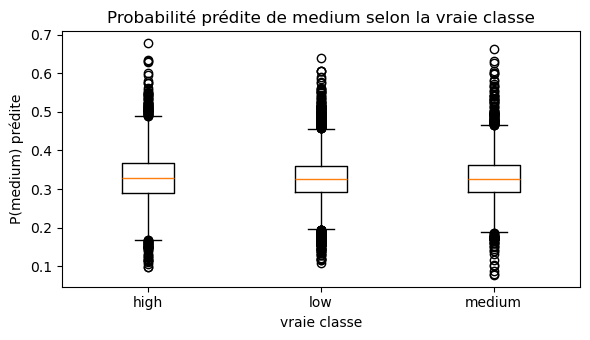

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.boxplot([proba_base_test[y_test == k, MED] for k in IDS])
ax.set_xticklabels(CLASSES)
ax.set_xlabel("vraie classe"); ax.set_ylabel("P(medium) prédite"); ax.set_title("Probabilité prédite de medium selon la vraie classe")
plt.tight_layout(); plt.show()

**Lecture :** si la probabilité de medium est presque identique quelle que soit la vraie classe, et si les AUC « medium vs reste »
sont proches de 0,5, medium est une classe « du milieu » qui ressemble aux deux autres : c'est une **limite des données**.
Le modèle prédit alors presque toujours low ou high parce que P(medium) n'est presque jamais la plus grande.

## 5. Améliorations (choix faits sur la validation, jamais sur le test)

In [9]:
def add_features(df):
    """Variables calculées uniquement à partir des autres colonnes (aucune utilisation de la cible)."""
    d = df.copy()
    t = d["tenure_months"] + 1
    d["spend_per_tenure"] = d["avg_monthly_spend_ngn"] / t
    d["late_rate"] = d["late_payment_count"] / t
    d["spend_per_recharge"] = d["avg_monthly_spend_ngn"] / (d["recharge_frequency_per_month"] + 1)
    d["score_x_consistency"] = d["credit_score"] * d["payment_consistency_score"]
    return d


def fit_candidate(params, w_balanced, use_fe, early_stop):
    Xf = add_features(X_fit) if use_fe else X_fit
    Xv = add_features(X_val) if use_fe else X_val
    cat = [c for c in Xf.columns if c in CAT]
    num = [c for c in Xf.columns if c not in CAT]
    prep = make_prep(cat, num).fit(Xf)
    p = dict(BASE_PARAMS, **params)
    if early_stop:
        p["early_stopping_rounds"] = 50
    m = XGBClassifier(**p)
    sw = compute_sample_weight("balanced", y_fit) if w_balanced else None
    m.fit(prep.transform(Xf), y_fit, sample_weight=sw,
          eval_set=[(prep.transform(Xv), y_val)], verbose=False)
    return {"prep": prep, "model": m, "use_fe": use_fe}


def proba_of(c, df):
    d = add_features(df) if c["use_fe"] else df
    return c["model"].predict_proba(c["prep"].transform(d))


def tune_class_weights(y_true, proba):
    """Cherche des multiplicateurs (high, low=1, medium) qui maximisent le F1 macro sur la validation."""
    best = (-1, None)
    for w_med in np.arange(0.8, 4.01, 0.1):
        for w_high in np.arange(0.6, 2.01, 0.1):
            w = np.ones(len(CLASSES)); w[MED] = w_med; w[CLASSES.index("high")] = w_high
            f = f1_score(y_true, np.argmax(proba * w, axis=1), average="macro")
            if f > best[0]:
                best = (f, w)
    return best[1]


REG = dict(max_depth=4, learning_rate=0.05, n_estimators=1000, min_child_weight=20, reg_lambda=5.0)
CANDIDATES = {
    "A_reference (train.py)":              dict(params={},  w_balanced=True,  use_fe=False, early_stop=False),
    "B_regularise + early stopping":       dict(params=REG, w_balanced=True,  use_fe=False, early_stop=True),
    "C_regularise sans poids":             dict(params=REG, w_balanced=False, use_fe=False, early_stop=True),
    "D_regularise + variables calculées":  dict(params=REG, w_balanced=True,  use_fe=True,  early_stop=True),
}
fitted, rows = {}, []
for name, cfg in CANDIDATES.items():
    print("Entraînement :", name, "...")
    c = fit_candidate(**cfg)
    pv = proba_of(c, X_val)
    w = tune_class_weights(y_val, pv)
    c["weights"] = w
    fitted[name] = c
    raw, tuned = metrics_from_proba(y_val, pv), metrics_from_proba(y_val, pv, w)
    rows.append({"essai": name,
                 "AUC val": raw["auc_macro_ovr"],
                 "F1 macro (argmax)": raw["f1_macro"],
                 "rappel medium (argmax)": raw["per_class"]["medium"]["recall"],
                 "F1 macro (poids réglés)": tuned["f1_macro"],
                 "rappel medium (poids)": tuned["per_class"]["medium"]["recall"],
                 "F1 medium (poids)": tuned["per_class"]["medium"]["f1-score"],
                 "poids [high, low, medium]": [round(float(x), 1) for x in w]})
comparison = pd.DataFrame(rows).set_index("essai")
comparison.round(4)

Entraînement : A_reference (train.py) ...
Entraînement : B_regularise + early stopping ...
Entraînement : C_regularise sans poids ...
Entraînement : D_regularise + variables calculées ...


,AUC val,F1 macro (argmax),rappel medium (argmax),F1 macro (poids réglés),rappel medium (poids),F1 medium (poids),"poids [high, low, medium]"
essai,,,,,,,
A_reference (train.py),0.6502,0.4688,0.0479,0.4818,0.1337,0.1797,"[0.7, 1.0, 1.0]"
B_regularise + early stopping,0.6454,0.4539,0.0000,0.4811,0.1091,0.1603,"[0.6, 1.0, 1.0]"
C_regularise sans poids,0.6728,0.4537,0.0000,0.4790,0.1223,0.1717,"[1.8, 1.0, 2.9]"
D_regularise + variables calculées,0.6470,0.4539,0.0000,0.4830,0.1153,0.1669,"[0.6, 1.0, 1.0]"


Les « poids réglés » sont de simples multiplicateurs appliqués aux probabilités avant de prendre la classe la plus probable.
Cela change la **règle de décision**, pas l'algorithme : XGBoost reste le seul modèle. Ils sont choisis sur la validation uniquement.

In [10]:
best_name = comparison["F1 macro (poids réglés)"].idxmax()
best = fitted[best_name]
print("Essai retenu (meilleur F1 macro sur la validation) :", best_name)
print("Poids [high, low, medium] :", [round(float(x), 2) for x in best["weights"]])

Essai retenu (meilleur F1 macro sur la validation) : D_regularise + variables calculées
Poids [high, low, medium] : [0.6, 1.0, 1.0]


## 6. Évaluation finale sur le jeu de test (une seule fois)

In [11]:
proba_final_test = proba_of(best, X_test)
final = metrics_from_proba(y_test, proba_final_test, best["weights"])

table = pd.DataFrame({
    "avant": [baseline["accuracy"], baseline["f1_macro"], baseline["auc_macro_ovr"],
              *[baseline["per_class"][c][k] for c in CLASSES for k in ("precision", "recall", "f1-score")]],
    "après": [final["accuracy"], final["f1_macro"], final["auc_macro_ovr"],
              *[final["per_class"][c][k] for c in CLASSES for k in ("precision", "recall", "f1-score")]],
}, index=["accuracy", "F1 macro", "AUC macro (OvR)",
          *[f"{k} {c}" for c in CLASSES for k in ("précision", "rappel", "F1")]])
table["écart"] = table["après"] - table["avant"]
table.round(4)

,avant,après,écart
accuracy,0.6275,0.6240,-0.0034
F1 macro,0.4709,0.4834,0.0125
AUC macro (OvR),0.6583,0.6497,-0.0086
précision high,0.5027,0.5016,-0.0011
rappel high,0.6706,0.5046,-0.1660
F1 high,0.5746,0.5031,-0.0715
précision low,0.7030,0.7034,0.0004
rappel low,0.8589,0.8888,0.0299
F1 low,0.7732,0.7853,0.0121
précision medium,0.2433,0.3003,0.0570


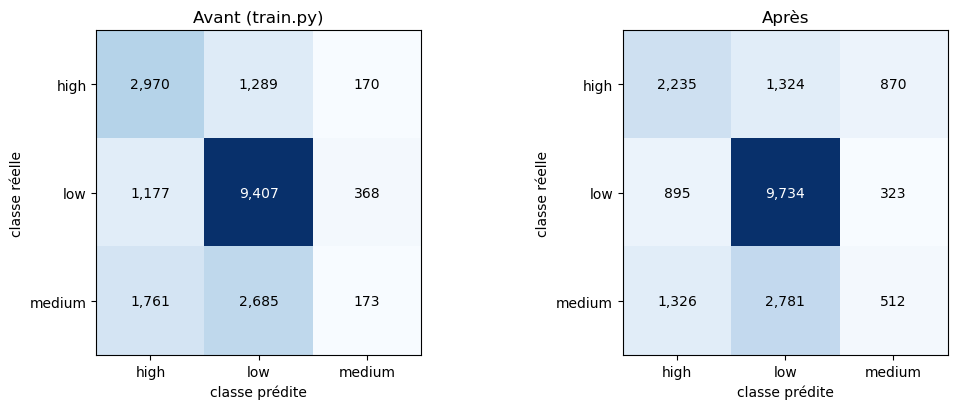

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, (title, res) in zip(ax, [("Avant (train.py)", baseline), ("Après", final)]):
    m = np.array(res["confusion_matrix"])
    a.imshow(m, cmap="Blues")
    a.set_xticks(IDS, CLASSES); a.set_yticks(IDS, CLASSES)
    a.set_xlabel("classe prédite"); a.set_ylabel("classe réelle"); a.set_title(title)
    for i in IDS:
        for j in IDS:
            a.text(j, i, f"{m[i, j]:,}", ha="center", va="center",
                   color="white" if m[i, j] > m.max() / 2 else "black")
plt.tight_layout()
plt.savefig(REPORTS / "confusion_matrix_xgboost.png", dpi=130, bbox_inches="tight")
plt.show()

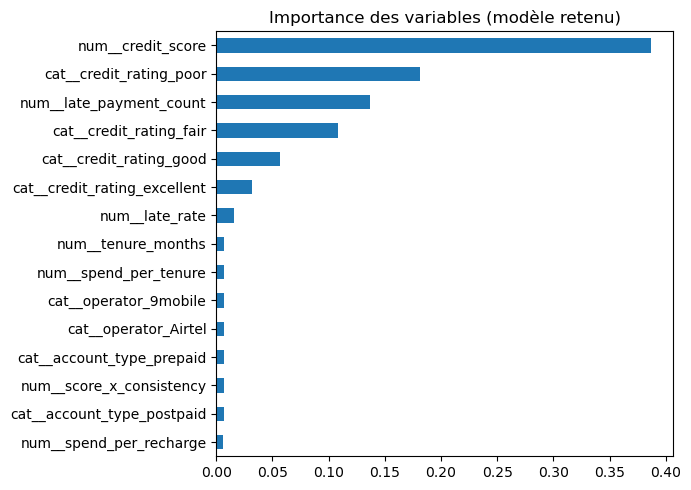

In [13]:
# Importance des variables du modèle retenu (à interpréter avec prudence)
names = best["prep"].get_feature_names_out()
imp = pd.Series(best["model"].feature_importances_, index=names).sort_values(ascending=False).head(15)
imp[::-1].plot.barh(figsize=(7, 5), title="Importance des variables (modèle retenu)")
plt.tight_layout(); plt.savefig(REPORTS / "feature_importance_xgboost.png", dpi=130, bbox_inches="tight"); plt.show()

## 7. Enregistrement des métriques et des limites

In [14]:
medium_before = baseline["per_class"]["medium"]["recall"]
medium_after = final["per_class"]["medium"]["recall"]
limits = f"""# Limites du modèle XGBoost (issue #2)

- Séparation reproductible : test_size={TEST_SIZE}, random_state={SEED}, stratifiée. Choix des réglages sur une validation extraite du train ; le test n'est utilisé qu'une fois.
- Résultat final sur le test : F1 macro = {final['f1_macro']:.3f} (avant : {baseline['f1_macro']:.3f}), AUC macro = {final['auc_macro_ovr']:.3f} (avant : {baseline['auc_macro_ovr']:.3f}).
- Classe medium : rappel {medium_before:.3f} -> {medium_after:.3f}, F1 {baseline['per_class']['medium']['f1-score']:.3f} -> {final['per_class']['medium']['f1-score']:.3f}.
- Le gain sur medium se paie par une baisse de la précision ou du rappel des autres classes (voir le tableau avant/après) : c'est un compromis, pas une amélioration gratuite.
- L'AUC macro reste modeste : les variables disponibles séparent mal la classe medium des classes low et high. Une classe « du milieu » chevauche les deux autres.
- Aucun score de 90 % n'est garanti : il ne serait pas justifié par ces données.
- Variables à vérifier : credit_score et credit_rating (voir l'audit de fuite). Elles ne sont pas retirées automatiquement ; la décision dépend de la façon dont le jeu de données a été généré.
- Les poids de classes [high, low, medium] = {[round(float(x), 2) for x in best['weights']]} sont réglés sur la validation ; ils devront être revalidés si les données dérivent.
- Le modèle final est entraîné sur 80 % du train (les 20 % restants servent à la validation), alors que la référence utilise tout le train : la comparaison reste à mettre en regard de cette différence.
- Données synthétiques : les résultats ne se transposent pas tels quels à des données réelles.
"""
(REPORTS / "limites_xgboost.md").write_text(limits, encoding="utf-8")

report = {
    "issue": 2, "algorithm": "XGBoost", "target": TARGET, "classes": CLASSES,
    "split": {"test_size": TEST_SIZE, "val_size_of_train": VAL_SIZE, "random_state": SEED, "stratified": True,
              "rows": {"fit": len(X_fit), "val": len(X_val), "test": len(X_test)}},
    "selected_experiment": best_name,
    "selected_parameters": {k: v for k, v in best["model"].get_params().items()
                            if k in ("n_estimators", "max_depth", "learning_rate", "min_child_weight",
                                     "reg_lambda", "subsample", "colsample_bytree")},
    "best_iteration": int(getattr(best["model"], "best_iteration", -1) or -1),
    "uses_engineered_features": best["use_fe"],
    "baseline_test": baseline, "final_test": final,
    "validation_comparison": comparison.reset_index().to_dict(orient="records"),
    "leakage_audit": audit.to_dict(orient="records"),
    "library_versions": {"scikit_learn": sklearn.__version__, "xgboost": xgboost.__version__},
}
(REPORTS / "xgboost_evaluation.json").write_text(json.dumps(report, indent=2, default=float), encoding="utf-8")
print("Écrits dans reports/ : xgboost_evaluation.json, limites_xgboost.md, confusion_matrix_xgboost.png, feature_importance_xgboost.png")

if SAVE_MODEL:
    import joblib
    joblib.dump({"prep": best["prep"], "model": best["model"], "class_weights": best["weights"],
                 "classes": CLASSES, "uses_engineered_features": best["use_fe"]},
                ROOT / "models" / "default_risk_model_improved.joblib")

print(limits)

Écrits dans reports/ : xgboost_evaluation.json, limites_xgboost.md, confusion_matrix_xgboost.png, feature_importance_xgboost.png
# Limites du modèle XGBoost (issue #2)

- Séparation reproductible : test_size=0.2, random_state=42, stratifiée. Choix des réglages sur une validation extraite du train ; le test n'est utilisé qu'une fois.
- Résultat final sur le test : F1 macro = 0.483 (avant : 0.471), AUC macro = 0.650 (avant : 0.658).
- Classe medium : rappel 0.037 -> 0.111, F1 0.065 -> 0.162.
- Le gain sur medium se paie par une baisse de la précision ou du rappel des autres classes (voir le tableau avant/après) : c'est un compromis, pas une amélioration gratuite.
- L'AUC macro reste modeste : les variables disponibles séparent mal la classe medium des classes low et high. Une classe « du milieu » chevauche les deux autres.
- Aucun score de 90 % n'est garanti : il ne serait pas justifié par ces données.
- Variables à vérifier : credit_score et credit_rating (voir l'audit de fuite). Elles 